# TP5 — Optimiser (1/2) : surapprentissage et régularisation
**ÉNONCÉ** · Durée estimée : **une demi-journée**

## 🎯 Ce que vous allez apprendre
- **Provoquer** puis reconnaître le surapprentissage sur des courbes
- Appliquer quatre remèdes : **arrêt précoce, dropout, L2, réseau plus petit**
- Mesurer le **bruit** pour savoir si une amélioration est **réelle**
- Fabriquer de nouvelles données : l'**augmentation de données**

## 🧰 Boîte à outils
Noms de fonctions et de classes utiles. **Aucun exemple d'appel n'est donné** : cherchez dans la documentation (scikit-learn, Keras, NumPy, matplotlib) comment les utiliser.

`EarlyStopping`  ·  `layers.Dropout`  ·  `regularizers.l2`  ·  `kernel_regularizer`  ·  `np.std`  ·  `np.sqrt`  ·  `np.roll`  ·  `np.concatenate`  ·  `set_random_seed`

## 📘 Comment travailler
- Les cellules **déjà écrites** sont à lire et à exécuter.
- Les cellules **🎯 Étape** sont à **écrire vous-même**, à partir de la consigne.
- Après chaque étape, une cellule **✅ Contrôle** vérifie votre résultat. Respectez les **noms de variables** demandés.
- Les questions **✍️** demandent une réponse écrite : c'est là que vous montrez que vous avez compris.
- Bloqué ? Relisez l'indice, puis cherchez dans la documentation. Un message d'erreur se lit : la dernière ligne dit souvent ce qui ne va pas.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, confusion_matrix, precision_score, recall_score
from tensorflow import keras
from tensorflow.keras import layers, regularizers
keras.utils.set_random_seed(42)

def controle(condition, ok, ko):
    print("✅", ok) if condition else print("❌", ko)

## Étape 1 — Préparer : un petit jeu pour provoquer le surapprentissage
On reprend les chiffres, mais on n'utilise que **300 images** pour apprendre. Avec peu de données et un gros réseau, la mémorisation est facile. Deux petites fonctions utilitaires sont fournies.

In [2]:
from sklearn.datasets import load_digits
chiffres = load_digits()
X = chiffres.data / 16.0
y = chiffres.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
petit_X, petit_y = X_train[:300], y_train[:300]

def courbes(histoire):
    h = histoire.history
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
    ax[0].plot(h["loss"], label="apprentissage"); ax[0].plot(h["val_loss"], label="validation"); ax[0].set_title("Perte"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(h["accuracy"], label="apprentissage"); ax[1].plot(h["val_accuracy"], label="validation"); ax[1].set_title("Précision"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout(); plt.show()

def precision_test(modele, entrees=None):
    entrees = X_test if entrees is None else entrees
    return float(np.mean(np.argmax(modele.predict(entrees, verbose=0), axis=1) == y_test))

print(petit_X.shape, "images pour apprendre |", X_test.shape[0], "pour le test")

(300, 64) images pour apprendre | 450 pour le test


## 🎯 Étape 2 — Une fonction pour construire des réseaux variés
Pour comparer plusieurs réglages, on écrit **une fonction** qui construit le réseau à la demande. Le **dropout** éteint au hasard une proportion de neurones à chaque pas d'apprentissage, pour que le réseau ne s'appuie pas sur un seul neurone. La **régularisation L2** ajoute une pénalité sur les gros poids.

**À faire :** Écrivez `construire(neurones=256, dropout=0.0, l2=0.0, seed=42)` qui fixe la graine puis renvoie un modèle **compilé** : entrée 64, **deux couches Dense de `neurones` (ReLU)**, chacune suivie d'un `Dropout(dropout)`, avec `kernel_regularizer=regularizers.l2(l2)` si `l2 > 0`, puis une sortie **Dense 10 softmax**. Optimiseur adam, perte sparse_categorical_crossentropy, métrique accuracy.

> 💡 **Indice** : `layers.Dropout(0.0)` ne fait rien : pas besoin de le traiter à part. `regularizers.l2(valeur)`.

In [4]:
def construire(neurones=256, dropout=0.0, l2=0.0, seed=42):
    """
    Fabrique et compile un réseau de classification (64 entrées → 10 classes).

    Paramètres :
        neurones : nombre de neurones par couche cachée
        dropout  : taux de Dropout (0.0 = désactivé)
        l2       : coefficient de régularisation L2 (0.0 = désactivé)
        seed     : graine pour la reproductibilité

    Retourne : un modèle Keras compilé, prêt pour .fit().
    """
    # Reproductibilité : fixe les graines de Python, NumPy et TF
    keras.utils.set_random_seed(seed)

    # Régularisateur L2 partagé par toutes les couches Dense cachées.
    # None si l2 == 0 → équivalent à ne rien passer (pas de duplication de code).
    regul = regularizers.l2(l2) if l2 > 0 else None

    # Pile de couches, démarrée par la forme d'entrée (64 features)
    couches = [layers.Input(shape=(64,))]

    # 2 couches cachées : Dense ReLU (+ L2) puis Dropout si demandé.
    # Dropout(0.0) étant une couche no-op, on la saute quand dropout == 0.
    for _ in range(2):
        couches.append(
            layers.Dense(neurones, activation='relu', kernel_regularizer=regul)
        )
        if dropout > 0:
            couches.append(layers.Dropout(dropout))

    # Couche de sortie : softmax → probabilités sur les 10 classes
    couches.append(layers.Dense(10, activation='softmax'))

    # Assemblage en Sequential
    modele = keras.Sequential(couches)

    # Compilation en place : le modèle est prêt pour .fit()
    modele.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',  # labels entiers 0-9, pas de one-hot
        metrics=['accuracy'],
    )

    return modele


In [5]:
# ✅ Contrôle (ne pas modifier)
controle(construire().count_params() == 85002 and construire(neurones=16).count_params() == 1482, 'Fonction correcte', 'Attendu 85 002 paramètres par défaut et 1 482 avec 16 neurones')

✅ Fonction correcte


## 🎯 Étape 3 — Provoquer le surapprentissage
Un réseau de 256 + 256 neurones (85 000 paramètres) pour apprendre sur **300 images** : il a largement de quoi **tout mémoriser**.

**À faire :** Créez `gros = construire()`. Entraînez-le sur `petit_X`, `petit_y` : **150 epochs**, batch de 32, **20 % de validation**, sans affichage → `histoire_gros`. Affichez les courbes avec `courbes(histoire_gros)` et calculez `acc_gros` (précision test avec `precision_test`).

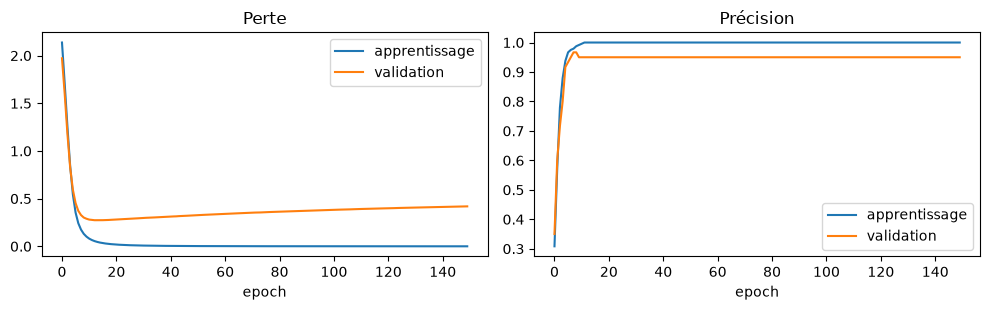

In [6]:
gros = construire()
# TODO : entraîner, afficher les courbes, calculer acc_gros

histoire_gros = gros.fit(petit_X, petit_y, epochs=150, batch_size=32, validation_split=0.2, verbose=0)
courbes(histoire_gros)
acc_gros = precision_test(gros)


In [7]:
# ✅ Contrôle (ne pas modifier)
h = histoire_gros.history
controle(h['accuracy'][-1] > 0.99 and h['val_loss'][-1] > min(h['val_loss']), 'Surapprentissage provoqué : la perte de validation a remonté', 'Attendu : précision d\'apprentissage > 0.99 et perte de validation finale > son minimum')

✅ Surapprentissage provoqué : la perte de validation a remonté


### ✍️ Question
**Décrivez ce que vous voyez sur la courbe de perte. À partir de quand le réseau surapprend-il ? La précision de validation baisse-t-elle autant que la perte de validation remonte ?**

*Votre réponse (2 à 4 lignes) :*

> Sur la courbe de perte, on observe une diminution rapide de la perte d'apprentissage (bleu) dès les premières époques, tandis que la perte de validation (orange) se stabilise autour de l'époque 10, puis remonte faiblement de manière continue à partir de l'époque 20. Cela indique un début de surapprentissage vers l'époque 20, où le modèle mémorise les données d'entraînement au détriment de la généralisation. Concernant la précision, la précision de validation (orange) reste stable autour de 0.95 après une montée initiale, alors que la perte de validation augmente légèrement. Ainsi, la baisse de précision de validation n'est pas aussi marquée que la remontée de la perte de validation, suggérant une dégradation modérée des performances.

## 🎯 Étape 4 — Comparer les remèdes
Même petit jeu, mêmes données, **cinq façons** de limiter le surapprentissage :
1. réseau de base, sans remède (référence) ;
2. **arrêt précoce** (patience 10, `restore_best_weights=True`) ;
3. **dropout 0,3** ;
4. **L2 = 1e-3** ;
5. **réseau plus petit** (16 neurones).

**À faire :** Pour chacune, entraînez avec `construire` (150 epochs max, batch 32, 20 % de validation) et rangez dans un tableau pandas **`resultats`** : `configuration`, `perte validation min`, `perte validation finale`, `epochs` effectués, `précision test`.

> 💡 **Indice** : Une boucle sur un dictionnaire de configurations. L'arrêt précoce se passe via `callbacks=[...]` dans `fit`. `len(histoire.history['loss'])` donne les epochs effectués.

In [32]:
# Colonnes du tableau final
colonnes = ['configuration', 'perte validation min', 'perte validation finale', 'epochs', 'précision test']

# Chaque configuration = les arguments nommés à passer à construire().
# 'base' et 'arret precoce' n'en ont aucun (valeurs par défaut) ;
# l'arrêt précoce se distinguera par son callback, pas par ses hyperparamètres.
configurations = {
    'base': {},                    # référence : réseau complet, aucun remède
    'arret precoce': {},           # même réseau, mais arrêt anticipé de l'entraînement
    'L2': {'l2': 1e-3},            # pénalité sur les gros poids
    'dropout': {'dropout': 0.3},   # 30 % de neurones éteints au hasard à chaque pas
    'petit': {'neurones': 16},     # réseau réduit (16 au lieu de 256 par couche)
}

# On accumule les résultats dans une liste de dicts,
# puis on assemble le DataFrame à la fin.
# (Assigner des colonnes sur un DataFrame vide n'ajoute aucune ligne.)
lignes = []

for name, kwargs in configurations.items():
    # Fabrique un modèle frais avec les hyperparamètres de la config.
    # **kwargs dépaquette le dict : {'dropout': 0.3} → construire(dropout=0.3)
    modele = construire(**kwargs)

    # Callback d'arrêt précoce uniquement pour la config concernée :
    # - patience=10 : stoppe si la perte de validation ne s'améliore plus pendant 10 epochs
    # - restore_best_weights=True : revient aux meilleurs poids (pas aux derniers)
    callbacks = [keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)] if name == 'arret precoce' else None

    # Même petit jeu que l'étape 3 (300 images), 150 epochs max, batch 32, 20 % de validation.
    # Sans verbose : rien d'affiché pendant l'entraînement.
    histoire = modele.fit(petit_X, petit_y, epochs=150, batch_size=32, validation_split=0.2, verbose=0, callbacks=callbacks)

    # Historique : une valeur par epoch pour chaque grandeur suivie
    h = histoire.history

    # Une ligne par configuration
    lignes.append({
        'configuration': name,
        'perte validation min': min(h['val_loss']),     # le meilleur point atteint (avant surapprentissage)
        'perte validation finale': h['val_loss'][-1],   # la dernière : remontée = surapprentissage
        'epochs': len(h['loss']),                       # nombre d'epochs réellement effectuées (< 150 si arrêt précoce)
        'précision test': precision_test(modele),       # précision sur le jeu de TEST (pas celle de l'entraînement !)
    })

# Assemblage final : 5 lignes, une par configuration
resultats = pd.DataFrame(lignes, columns=colonnes)

In [33]:
display(resultats)

,configuration,perte validation min,perte validation finale,epochs,précision test
0,base,0.273205,0.419090,150,0.908889
1,arret precoce,0.273205,0.287709,25,0.915556
2,L2,0.317993,0.318305,150,0.911111
3,dropout,0.245811,0.325333,150,0.913333
4,petit,0.332749,0.334203,150,0.900000


In [34]:
# ✅ Contrôle (ne pas modifier)
controle(len(resultats) == 5 and (resultats['précision test'] > 0.8).all(), 'Tableau de 5 configurations', 'Attendu 5 lignes avec des précisions de test > 0.8')

✅ Tableau de 5 configurations


## Étape 5 — Combien de bruit ? Une différence de précision est-elle réelle ?
Avec 450 images de test, la précision d'un modèle est connue avec une **marge d'incertitude** : tester sur d'autres 450 images donnerait un résultat légèrement différent. Cette marge vaut environ `1,96 × √(p(1−p)/n)`. **Une différence plus petite que cette marge n'est pas une amélioration démontrée.**

In [35]:
p = resultats["précision test"].mean()
bruit = 1.96 * np.sqrt(p * (1 - p) / len(y_test))
print(f"Avec {len(y_test)} images de test, une différence inférieure à environ {bruit:.3f} est dans le bruit.")
print("Écart entre la meilleure et la moins bonne précision test du tableau :", round(resultats["précision test"].max() - resultats["précision test"].min(), 3))

Avec 450 images de test, une différence inférieure à environ 0.026 est dans le bruit.
Écart entre la meilleure et la moins bonne précision test du tableau : 0.016


### ✍️ Question
**Quel remède vous paraît le meilleur ? Les écarts de précision dépassent-ils le bruit ? Quelle autre colonne du tableau permet de mieux les distinguer ?**

*Votre réponse (2 à 4 lignes) :*

> L’arrêt précoce semblre etre le remède le plus efficace (précision test 0.9156, perte validation finale 0.2877), mais les écarts de précision (max 1.56 %) restent inférieurs à la marge de bruit (2.6 %), donc aucune différence n’est statistiquement significative. La colonne perte validation min permet de mieux distinguer les configurations, car elle reflète la performance avant le surapprentissage.

## 🎯 Étape 6 — Mesurer la variabilité : un résultat dépend aussi de la graine
Le hasard intervient partout (poids de départ, ordre des données). Un même réglage donne donc des résultats légèrement différents d'une exécution à l'autre. **Avant de conclure qu'un réglage est meilleur, on le répète.**

**À faire :** Pour la configuration de **base** puis pour **`dropout=0.3`**, entraînez **5 modèles** avec les graines `0, 1, 2, 3, 4` (100 epochs, batch 32, sans validation). Rangez les précisions test dans deux listes `acc_base` et `acc_dropout`. Affichez moyenne ± écart-type de chacune.

> 💡 **Indice** : `construire(seed=s)` fixe la graine. `np.mean`, `np.std`.

In [ ]:
acc_base, acc_dropout = [], []
# TODO : 5 graines pour chaque configuration
for s in range(5):
    # Modele de base
    model = construire(seed=s)
    model.fit(petit_X, petit_y, epochs=100, batch_size=32, verbose=0)
    acc_base.append(precision_test(model))
    # Modele avec dropout
    model = construire(dropout=0.3, seed=s)
    model.fit(petit_X, petit_y, epochs=100, batch_size=32, verbose=0)
    acc_dropout.append(precision_test(model))

Moyennes ± écart-type :
- Base : 0.94 ± 0.01
- Dropout : 0.94 ± 0.01


In [39]:
print(f"Moyennes ± écart-type :\n- Base : {np.mean(acc_base):.2%} ± {np.std(acc_base):.2%}\n- Dropout : {np.mean(acc_dropout):.2%} ± {np.std(acc_dropout):.2%}") 

Moyennes ± écart-type :
- Base : 94.22% ± 0.64%
- Dropout : 93.82% ± 0.65%


In [37]:
# ✅ Contrôle (ne pas modifier)
controle(len(acc_base) == 5 and len(acc_dropout) == 5, 'Deux séries de 5 entraînements', 'Attendu 5 valeurs dans chaque liste')

✅ Deux séries de 5 entraînements


### ✍️ Question
**Un écart de 1 point de précision entre deux configurations suffit-il à conclure que l'une est meilleure ?**

*Votre réponse (2 à 4 lignes) :*

> Pas vraiment, car ce 1 point est toujours dans la marge d'erreur. Il faudrait pouvoir tester sur ce plus grands jeux de données pour se renre véritablement si un modele est plus performant qu'un autre.

## Étape 7 — Préparer l'augmentation de données : un CNN et des images décalées
Au TP4, un petit décalage trompait les modèles. L'**augmentation de données** fabrique des variantes des images d'apprentissage (ici, décalées) pour que le modèle apprenne que **la position ne compte pas**. On reprend le CNN du TP4.

In [40]:
I_train = X_train.reshape(-1, 8, 8, 1)
I_test = X_test.reshape(-1, 8, 8, 1)
I_test_decale = np.roll(I_test, 1, axis=2)

def cnn(seed=42):
    keras.utils.set_random_seed(seed)
    m = keras.Sequential([layers.Input(shape=(8, 8, 1)), layers.Conv2D(16, 3, padding="same", activation="relu"), layers.MaxPooling2D(2),
                          layers.Conv2D(32, 3, activation="relu"), layers.Flatten(), layers.Dense(10, activation="softmax")])
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def precision_images(modele, images):
    return float(np.mean(np.argmax(modele.predict(images, verbose=0), axis=1) == y_test))
print(I_train.shape, I_test_decale.shape)

(1347, 8, 8, 1) (450, 8, 8, 1)


## 🎯 Étape 8 — Augmenter les données par décalage
⚠️ Deux règles : on n'augmente **que l'apprentissage, jamais le test** ; et on n'utilise pas ici de `validation_split` (il prendrait la fin du tableau, qui contiendrait des copies décalées d'images déjà vues).

**À faire :** Fabriquez `I_aug` et `y_aug` : les images d'apprentissage **plus leurs 4 versions décalées d'un pixel** (colonne +1, colonne −1, ligne +1, ligne −1). Entraînez `cnn_base` sur `I_train` et `cnn_aug` sur `I_aug` (**30 epochs**, batch 32, sans validation). Calculez les précisions sur `I_test` et `I_test_decale` dans un tableau `bilan`.

> 💡 **Indice** : `np.roll(I_train, 1, axis=2)` décale les colonnes ; `axis=1` les lignes. `np.concatenate([...])`. Les étiquettes `y_train` sont à répéter autant de fois.

In [41]:
# TODO : I_aug, y_aug, cnn_base, cnn_aug, bilan
I_aug = np.concatenate([
    # Images de base
    I_train,
    # Images décalées sur la ligne
    np.roll(I_train, -1, axis=1),
    np.roll(I_train, 1, axis=1),
    # Images décalées sur la colonne
    np.roll(I_train, -1, axis=2),
    np.roll(I_train, 1, axis=2)
])

# Version optimisé du script
# I_aug = np.concatenate(
#     [I_train]
#     + [np.roll(I_train, s, axis=ax) for ax in (1, 2) for s in (-1, 1)]
# )

y_aug = np.tile(y_train, 5) # equivalent a np.concatenate([y_train] * 5)

In [43]:
cnn_base = cnn()
cnn_base.fit(I_train, y_train, epochs=30, batch_size=32, verbose=0)

cnn_aug = cnn()
cnn_aug.fit(I_aug, y_aug, epochs=30, batch_size=32, verbose=0)

bilan = pd.DataFrame(
    [[precision_images(cnn_base, I_test), precision_images(cnn_base, I_test_decale)],
     [precision_images(cnn_aug, I_test), precision_images(cnn_aug, I_test_decale)]],
    columns=["images de base", "images décalées"],
)

In [45]:
display(bilan)

,images de base,images décalées
0,0.973333,0.557778
1,0.991111,0.971111


In [44]:
# ✅ Contrôle (ne pas modifier)
controle(len(I_aug) == 5 * len(I_train) and bilan.loc[1, 'images décalées'] > bilan.loc[0, 'images décalées'], "L'augmentation améliore nettement les images décalées", 'Attendu : 5 fois plus d\'images et une meilleure précision sur images décalées avec augmentation')

✅ L'augmentation améliore nettement les images décalées


### ✍️ Question
**Qu'a apporté l'augmentation ? Quelle est sa limite ?**

*Votre réponse (2 à 4 lignes) :*

> L'augmentation a permis d'améliorer la précision du modele sur les images décalés de ~42% (0.97 pour 0.56), et un tout petit peu sur les images de base (~2%). Cependant, l'augmentation a un cout en temps de calcul, car il fallut travailler un jeu de donnée cinq fois plus important.

## ✅ Ce qu'il faut retenir
- **Surapprentissage** : la perte d'apprentissage baisse, celle de validation **remonte**. La **précision** peut rester stable pendant ce temps, d'où l'intérêt de regarder la **perte**.
- Remèdes : **arrêt précoce, dropout, L2, réseau plus petit, plus de données** (ou augmentation).
- **Un gain n'existe que s'il dépasse le bruit** : bruit d'échantillonnage (taille du test) et variabilité entre graines.
- **L'augmentation de données** apprend au modèle ce qu'il doit ignorer. On n'augmente jamais le test.